# 1-01 당일 상장채권 — 하루·기간별 신규 상장 채권 목록과 건수

**질문 예시:** "오늘 거래소에 상장된 채권 뭐 있어?", "이번 달 날짜별로 채권 몇 건 상장됐어?"

옛 `krxnewsscrap/krxlistedbond.py`(Streamlit 앱)를 노트북으로 옮겼습니다. 앱은 KRX 상장채권 목록을 받아
상장일로 거른 뒤 하루치·기간 목록과 날짜별 건수 막대를 보여 줬습니다. 옮기면서 다음을 고쳤습니다.

| 항목 | 옛 앱 | 이 노트북 |
|---|---|---|
| 데이터 | `listed_bonds` (당시 CSV, 한글 컬럼) | `listed_bonds` (**JSON**, 영문 코드 컬럼을 직접 한글로 매핑) |
| 금액 단위 | "백만원"이라고 표시 (`money=2`) | `money=2`는 **천원**이었습니다. JSON은 `money`를 무시하고 항상 **원** → 억원으로 환산 |
| 채권 구분 | 없음 | 표준코드 셋째 자리로 국채·지방채·특수채·회사채 등 구분 |
| 과거 날짜 | 그냥 조회 | 이미 **상환된 채권은 목록에 없어** 과거일수록 건수가 줄어든다는 점을 표시 |

쓰는 엔드포인트: `listed_bonds` (KRX 14011 상장채권 상세검색, `MDCSTAT10801`)

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/krx-data-api/blob/main/scenarios/1_bonds/01_listed_bonds_by_date.ipynb)

## 0. 준비
2026-09부터 KRX는 로그인하지 않은 요청을 거절합니다. Colab 왼쪽 🔑(Secrets)에 `KRX_ID`, `KRX_PW`(KRX 정보데이터시스템 계정)를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다). 계정 값은 출력하지 않습니다.

In [1]:
# Colab에서만: krx-data-api 와 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install git+https://github.com/beaten-by-the-market/krx-data-api.git koreanize-matplotlib

In [2]:
# ── KRX 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────────────
# 2026-09부터 KRX는 비로그인 요청을 거절합니다. KRX 정보데이터시스템 계정이 필요합니다.
# Colab: 왼쪽 🔑(Secrets)에 KRX_ID, KRX_PW 를 넣고 "노트북 액세스"를 켜세요.
#        Secrets에 없으면 입력창으로 묻습니다. 아이디·비밀번호는 출력하지 않습니다.
# 로컬: krx_data_api 가 작업 폴더의 .env(또는 패키지를 클론한 레포의 .env)에서 KRX_ID/KRX_PW 를 읽습니다.
import os, sys
from datetime import date, datetime, timedelta

import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from getpass import getpass
    for _k in ("KRX_ID", "KRX_PW"):
        if os.environ.get(_k):
            continue
        try:
            from google.colab import userdata
            _v = userdata.get(_k)
        except Exception:
            _v = None
        os.environ[_k] = _v or getpass(f"{_k}: ")

from krx_data_api import fetch  # noqa: E402  (import 시 .env 로드)
from krx_data_api.daily_snapshots import trading_days  # noqa: E402

if not (os.environ.get("KRX_ID") and os.environ.get("KRX_PW")):
    raise RuntimeError("KRX_ID / KRX_PW 가 없습니다. Colab Secrets 또는 .env 에 넣어 주세요.")

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 40)


def num(s):
    """KRX JSON의 '1,234' 같은 콤마 문자열 → 숫자. '-'·빈 값은 NaN."""
    return pd.to_numeric(pd.Series(s).astype(str).str.replace(",", "", regex=False).str.strip(),
                         errors="coerce")


def ymd(d):
    """날짜 → 'YYYYMMDD' (KRX 파라미터 형식)."""
    return pd.Timestamp(d).strftime("%Y%m%d")


def last_trading_day(asof=None):
    """asof(기본 오늘) 또는 그 이전의 마지막 매매거래일 → Timestamp.
    KRX는 휴장일 trdDd에 직전 거래일 데이터를 그대로 주므로 날짜를 이걸로 맞춰 씁니다."""
    end = pd.Timestamp(asof or date.today())
    days = trading_days(ymd(end - timedelta(days=14)), ymd(end))
    return pd.Timestamp(days[-1])


def eok(won, digits=0):
    """원 → 억원 숫자."""
    return (pd.Series(won) / 1e8).round(digits)


# 한글 차트 폰트
import matplotlib.pyplot as plt  # noqa: E402
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("KRX 준비 완료", "(Colab)" if IN_COLAB else "(로컬)", "· 로그인 계정 설정됨")

KRX 준비 완료 (로컬) · 로그인 계정 설정됨


In [3]:
DAY = "2026-11-24"                          # 하루 조회 날짜
RANGE = ("2026-11-01", "2026-11-25")        # 기간 조회 (양 끝 포함)

## 1. 상장채권 전체 목록 받기
이 화면은 날짜 조건 없이 **지금 상장돼 있는 채권 전부**(약 1만 8천 종목)를 한 번에 돌려줍니다. 날짜 필터는 받은 뒤 직접 겁니다.

2026-07-02부터 `listed_bonds` 기본값은 JSON(영문 코드 컬럼, 콤마 문자열)이고, 한글 컬럼은 `listed_bonds_csv`가 줍니다.
여기서는 JSON을 쓰고 컬럼을 명시적으로 바꿉니다. 컬럼 이름이 바뀌면 바로 `KeyError`가 나도록 매핑에 없는 컬럼은 버리지 않고 확인합니다.

In [4]:
COLS = {  # JSON 코드 → 한글 (listed_bonds_csv 의 한글 컬럼명과 같은 뜻)
    "ISU_CD": "종목코드", "ISU_NM": "종목명", "LIST_DD": "상장일", "ISU_DD": "발행일",
    "REDMPT_DD": "상환일", "COUPN_RT": "표면금리", "ISU_AMT": "발행금액", "LIST_AMT": "상장금액",
}
raw = fetch("listed_bonds")
assert set(raw.columns) == set(COLS), f"컬럼이 바뀌었습니다: {sorted(raw.columns)}"
print("KRX 조회 시각:", raw.attrs.get("current_datetime"), "· 종목 수:", f"{len(raw):,}")

KIND = {"1": "국채", "2": "지방채", "3": "특수채", "6": "회사채", "B": "외국법인 원화채", "C": "국고채 원금·이자 분리"}
bonds = raw.rename(columns=COLS)
for c in ("상장일", "발행일"):
    bonds[c] = pd.to_datetime(bonds[c], format="%Y/%m/%d")
bonds["상환일"] = pd.to_datetime(bonds["상환일"].replace("9999/12/31", None), format="%Y/%m/%d")  # 9999-12-31 = 만기 없음
bonds["표면금리"] = num(bonds["표면금리"])
bonds["발행금액(억원)"] = eok(num(bonds["발행금액"]), 1)
bonds["상장금액(억원)"] = eok(num(bonds["상장금액"]), 1)
bonds["구분"] = bonds["종목코드"].str[2].map(KIND).fillna("기타")
bonds = bonds.drop(columns=["발행금액", "상장금액"])
bonds.head(3)

KRX 조회 시각: 2026.11.25 AM 06:52:32 · 종목 수: 17,842


,종목코드,종목명,상장일,발행일,상환일,표면금리,발행금액(억원),상장금액(억원),구분
0,KR6496452EB4,2024기보제이차유동화전문1-2(녹),2024-11-15,2024-11-14,2027-11-14,3.356,305.0,305.0,회사채
1,KR6496453EB2,2024기보제이차유동화전문1-3(사),2024-11-15,2024-11-14,2027-11-14,3.356,1735.8,1735.8,회사채
2,KR6485721E67,2024기보제일차유동화전문1-1(녹),2024-06-21,2024-06-20,2027-06-20,3.487,390.1,390.1,회사채


### 금액 단위 확인 (JSON vs CSV)
KRX 화면의 `money` 파라미터는 **CSV에만** 적용됩니다. 같은 종목을 비교하면 이렇습니다.

| 방식 | `money` | 금액 단위 |
|---|---|---|
| JSON (`listed_bonds`) | 무시됨 | 원 (콤마 문자열) |
| CSV (`listed_bonds_csv`) | 1 / **2 (카탈로그 기본값)** / 3 | 원 / **천원** / 백만원 |

옛 앱은 `money=2` 결과를 "백만원"이라고 표시해 금액을 1,000배 작게 읽게 했습니다. 아래 셀이 실제 값으로 확인합니다.

In [5]:
csv = fetch("listed_bonds_csv")            # 카탈로그 기본 money=2
chk = raw[["ISU_CD", "ISU_AMT"]].merge(csv[["종목코드", "발행금액"]], left_on="ISU_CD", right_on="종목코드")
ratio = (num(chk["ISU_AMT"]) / chk["발행금액"]).round(6)
n1000 = int((ratio == 1000).sum())
print(f"JSON 금액 ÷ CSV(money=2) 금액 = 1000 인 종목: {n1000:,} / {ratio.notna().sum():,} (금액 0 등으로 비율을 못 구한 종목 {ratio.isna().sum()}개)")
print("→ CSV money=2 는 천원 단위입니다." if n1000 == ratio.notna().sum() else "→ 단위가 바뀌었습니다. 위 표를 다시 확인하세요.")

JSON 금액 ÷ CSV(money=2) 금액 = 1000 인 종목: 17,831 / 17,831 (금액 0 등으로 비율을 못 구한 종목 11개)
→ CSV money=2 는 천원 단위입니다.


## 2. 하루 상장 채권

In [6]:
day = pd.Timestamp(DAY)
one = bonds[bonds["상장일"] == day].sort_values("상장금액(억원)", ascending=False).reset_index(drop=True)
print(f"{day.date()} 상장 채권 {len(one)}종목, 상장금액 합계 {one['상장금액(억원)'].sum():,.0f}억원")
show_cols = ["종목코드", "종목명", "구분", "발행일", "상환일", "표면금리", "발행금액(억원)", "상장금액(억원)"]
one[show_cols]

2026-11-24 상장 채권 40종목, 상장금액 합계 32,600억원


,종목코드,종목명,구분,발행일,상환일,표면금리,발행금액(억원),상장금액(억원)
0,KR310104AGB8,통화안정증권DC027-0223-0910,특수채,2026-11-24,2027-02-23,3.280,5500.0,5500.0
1,KR6000017GB9,신한은행30-11-이-1.5-A,회사채,2026-11-23,2028-05-23,3.990,4000.0,4000.0
2,KR6000033GB6,우리은행30-11-이표2.25-갑-23,회사채,2026-11-23,2029-02-23,4.030,2500.0,2500.0
3,KR381104GGB9,농업금융채권(중앙회)2026-11이3Y-D,특수채,2026-11-23,2029-11-23,4.000,2400.0,2400.0
4,KR6316141GB6,우리금융지주33,회사채,2026-11-23,2029-11-23,4.109,2400.0,2400.0
5,KR350705GGB0,한국도로공사고속도로건설채권1037,특수채,2026-11-13,2029-11-13,4.065,1600.0,1600.0
6,KR354419GGB4,한국주택금융공사318(사),특수채,2026-11-20,2028-11-20,3.978,1400.0,1400.0
7,KR6065909GB9,현대카드980-2,회사채,2026-11-23,2029-11-27,4.227,1200.0,1200.0
8,KR350704GGB3,한국도로공사고속도로건설채권1036,특수채,2026-11-13,2028-11-13,4.028,1100.0,1100.0
9,KR354603GGB3,한국철도공사296,특수채,2026-11-23,2030-05-23,3.996,1000.0,1000.0


In [7]:
one.groupby("구분").agg(종목수=("종목코드", "size"), 상장금액_억원=("상장금액(억원)", "sum"),
                      평균표면금리=("표면금리", "mean")).round(2).sort_values("상장금액_억원", ascending=False)

,종목수,상장금액_억원,평균표면금리
구분,,,
회사채,31,17500.0,4.49
특수채,9,15100.0,3.89


## 3. 기간별 상장 건수
날짜별 종목 수와 상장금액을 구분별로 쌓아 봅니다. 상장이 없는 날(휴장일 포함)은 표에서 빠집니다.

In [8]:
lo, hi = map(pd.Timestamp, RANGE)
rng = bonds[bonds["상장일"].between(lo, hi)]
by_day = rng.pivot_table(index="상장일", columns="구분", values="종목코드", aggfunc="size", fill_value=0)
by_day["합계"] = by_day.sum(axis=1)
by_day["상장금액(억원)"] = rng.groupby("상장일")["상장금액(억원)"].sum().round(0)
by_day.index = by_day.index.date
print(f"{lo.date()} ~ {hi.date()}: {len(rng)}종목, {by_day.shape[0]}일, 상장금액 합계 {rng['상장금액(억원)'].sum():,.0f}억원")
by_day

2026-11-01 ~ 2026-11-25: 412종목, 18일, 상장금액 합계 531,540억원


구분,국채,지방채,특수채,회사채,합계,상장금액(억원)
2026-11-02,1,19,12,47,79,25724.0
2026-11-03,0,0,20,4,24,57900.0
2026-11-04,0,0,22,3,25,34500.0
2026-11-05,0,0,2,11,13,18200.0
2026-11-06,0,0,23,28,51,109782.0
2026-11-09,0,1,2,16,19,17410.0
2026-11-10,1,0,17,8,26,44983.0
2026-11-11,0,0,6,24,30,32000.0
2026-11-12,0,0,8,9,17,23040.0
2026-11-13,0,2,0,26,28,28753.0


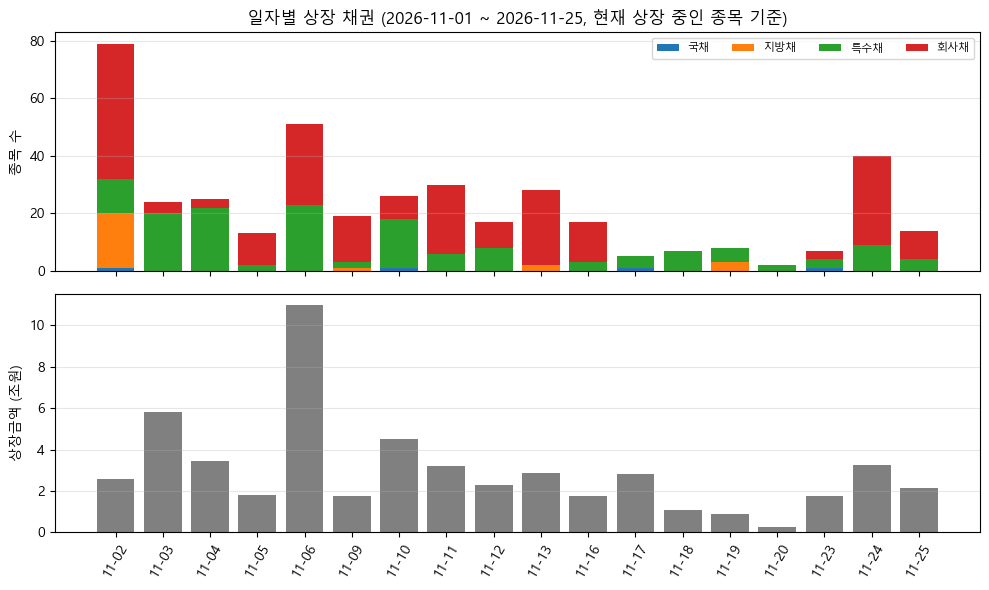

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
kinds = [c for c in by_day.columns if c not in ("합계", "상장금액(억원)")]
x = [str(d)[5:] for d in by_day.index]
bottom = np.zeros(len(by_day))
for k in kinds:
    axes[0].bar(x, by_day[k], bottom=bottom, label=k)
    bottom += by_day[k].values
axes[0].set_ylabel("종목 수"); axes[0].legend(ncol=len(kinds), fontsize=8); axes[0].grid(axis="y", alpha=.3)
axes[0].set_title(f"일자별 상장 채권 ({lo.date()} ~ {hi.date()}, 현재 상장 중인 종목 기준)")
axes[1].bar(x, by_day["상장금액(억원)"] / 1e4, color="gray")
axes[1].set_ylabel("상장금액 (조원)"); axes[1].grid(axis="y", alpha=.3)
plt.xticks(rotation=60); plt.tight_layout()

## 4. 과거 날짜를 볼 때 주의 — 상환된 채권은 목록에 없음
이 화면은 "현재 상장 중인 채권"만 줍니다. 가장 이른 상환일이 오늘 근처라는 것이 그 증거입니다.
만기가 짧은 채권(1~2년 은행채·카드채 등)은 이미 상환돼 빠졌으므로, **몇 달만 지나도 그날의 상장 건수는 실제보다 적게** 나옵니다.
연도별 건수가 최근으로 갈수록 늘어나는 것도 대부분 이 때문입니다(발행이 정말 늘어서가 아님).

In [10]:
print("가장 이른 상환일:", bonds["상환일"].min().date(), "· 만기 없음(9999-12-31):", bonds["상환일"].isna().sum(), "종목")
yearly = bonds.groupby(bonds["상장일"].dt.year).size().rename("현재 남아 있는 종목 수")
yearly.tail(8).to_frame().T

가장 이른 상환일: 2026-11-24 · 만기 없음(9999-12-31): 132 종목


상장일,2019,2020,2021,2022,2023,2024,2025,2026
현재 남아 있는 종목 수,322,496,516,1047,1353,2922,4691,5102


## 결과 읽는 법과 한계
- **당일 목록은 정확하지만 과거 목록은 불완전합니다.** 상장 후 상환·조기상환된 채권은 빠지므로, 과거 날짜의 "그날 상장 건수"를 정확히 알려면 그 날짜에 직접 받아 둔 스냅샷이 있어야 합니다.
- **상장일 ≠ 발행일.** 보통 발행 다음 거래일에 상장되지만, 발행보다 먼저 상장일이 잡힌 종목도 있습니다.
- **상장금액은 현재 상장 잔액으로 보입니다.** 약 560종목은 발행금액보다 작습니다(분할상환·매입소각 등으로 추정).
- **구분**은 표준코드 셋째 자리로 나눴습니다(1 국채, 2 지방채, 3 특수채, 6 회사채, B 외국법인 원화채, C 국고채 원금·이자 분리채권). 은행채·카드채·캐피탈채·유동화증권은 대부분 회사채(6), 공사채·통안채·중소기업은행채는 특수채(3)에 들어갑니다.
- 금액: JSON은 원 단위입니다. `listed_bonds_csv`를 쓰면 `money=1/2/3` = 원/천원/백만원이고 카탈로그 기본은 천원입니다.